In [ ]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from utils.plots import plot_forecast

## Buscando dados

In [ ]:
vale3_dataset = load_stock(STOCKS["vale"], "vale", force=True)
vale3_dataset.head(10)

In [ ]:
vale3_dataset

,date,vale_close,vale_high,vale_low,vale_open,vale_volume,ibovespa,vix,selic_daily,selic_goal,ipca,fx_usd,gdp,unemployment
0,2010-01-04,19.546476,19.546476,18.904923,19.052973,2381400,70045.0,20.040001,0.032927,8.75,0.75,1.7240,284387.8,NaN
1,2010-01-05,19.728693,19.945075,19.451573,19.565458,3001800,70240.0,19.350000,0.032927,8.75,0.75,1.7227,284387.8,NaN
2,2010-01-06,20.146265,20.260150,19.656559,19.740075,2742800,70729.0,19.160000,0.032927,8.75,0.75,1.7337,284387.8,NaN
3,2010-01-07,20.229790,20.324694,19.929892,19.933687,2543100,70451.0,19.059999,0.032927,8.75,0.75,1.7413,284387.8,NaN
4,2010-01-08,20.427187,20.590422,20.119697,20.233582,2444500,70263.0,18.129999,0.032927,8.75,0.75,1.7390,284387.8,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3969,2025-12-22,70.929672,71.367394,68.877263,69.091260,27853000,158142.0,14.080000,0.055131,15.00,0.33,5.5389,1084318.8,5.1
3970,2025-12-23,70.910225,71.523027,70.598959,71.231219,17140900,160456.0,14.000000,0.055131,15.00,0.33,5.5643,1084318.8,5.1
3971,2025-12-26,71.124222,71.347940,70.637869,70.871316,16368800,160897.0,13.600000,0.055131,15.00,0.33,5.5413,1084318.8,5.1
3972,2025-12-29,70.151512,71.727290,69.742970,71.192307,19963700,160490.0,14.200000,0.055131,15.00,0.33,5.5739,1084318.8,5.1


In [ ]:
print(vale3_dataset.isna().sum())

date              0
vale_close        0
vale_high         0
vale_low          0
vale_open         0
vale_volume       0
ibovespa          0
vix               0
selic_daily       0
selic_goal        0
ipca              0
fx_usd            0
gdp               0
unemployment    535
dtype: int64


## ARIMA

In [ ]:
train_vale, test_vale = split_temporal(vale3_dataset)
res_vale = run_arima(train_vale, test_vale, "vale")

--- Identificando ordem do ARIMA para VALE ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=6245.397, Time=1.11 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=6241.632, Time=0.09 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=6243.556, Time=0.07 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=6243.554, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=6240.425, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=6243.875, Time=0.39 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 1.841 seconds
Ordem ARIMA selecionada: (0, 1, 0)
ARIMA(0, 1, 0) vale    RMSE: 0.8408 | MAE: 0.6054 | MAPE: 1.14% | Acurácia direcional: 0.88%


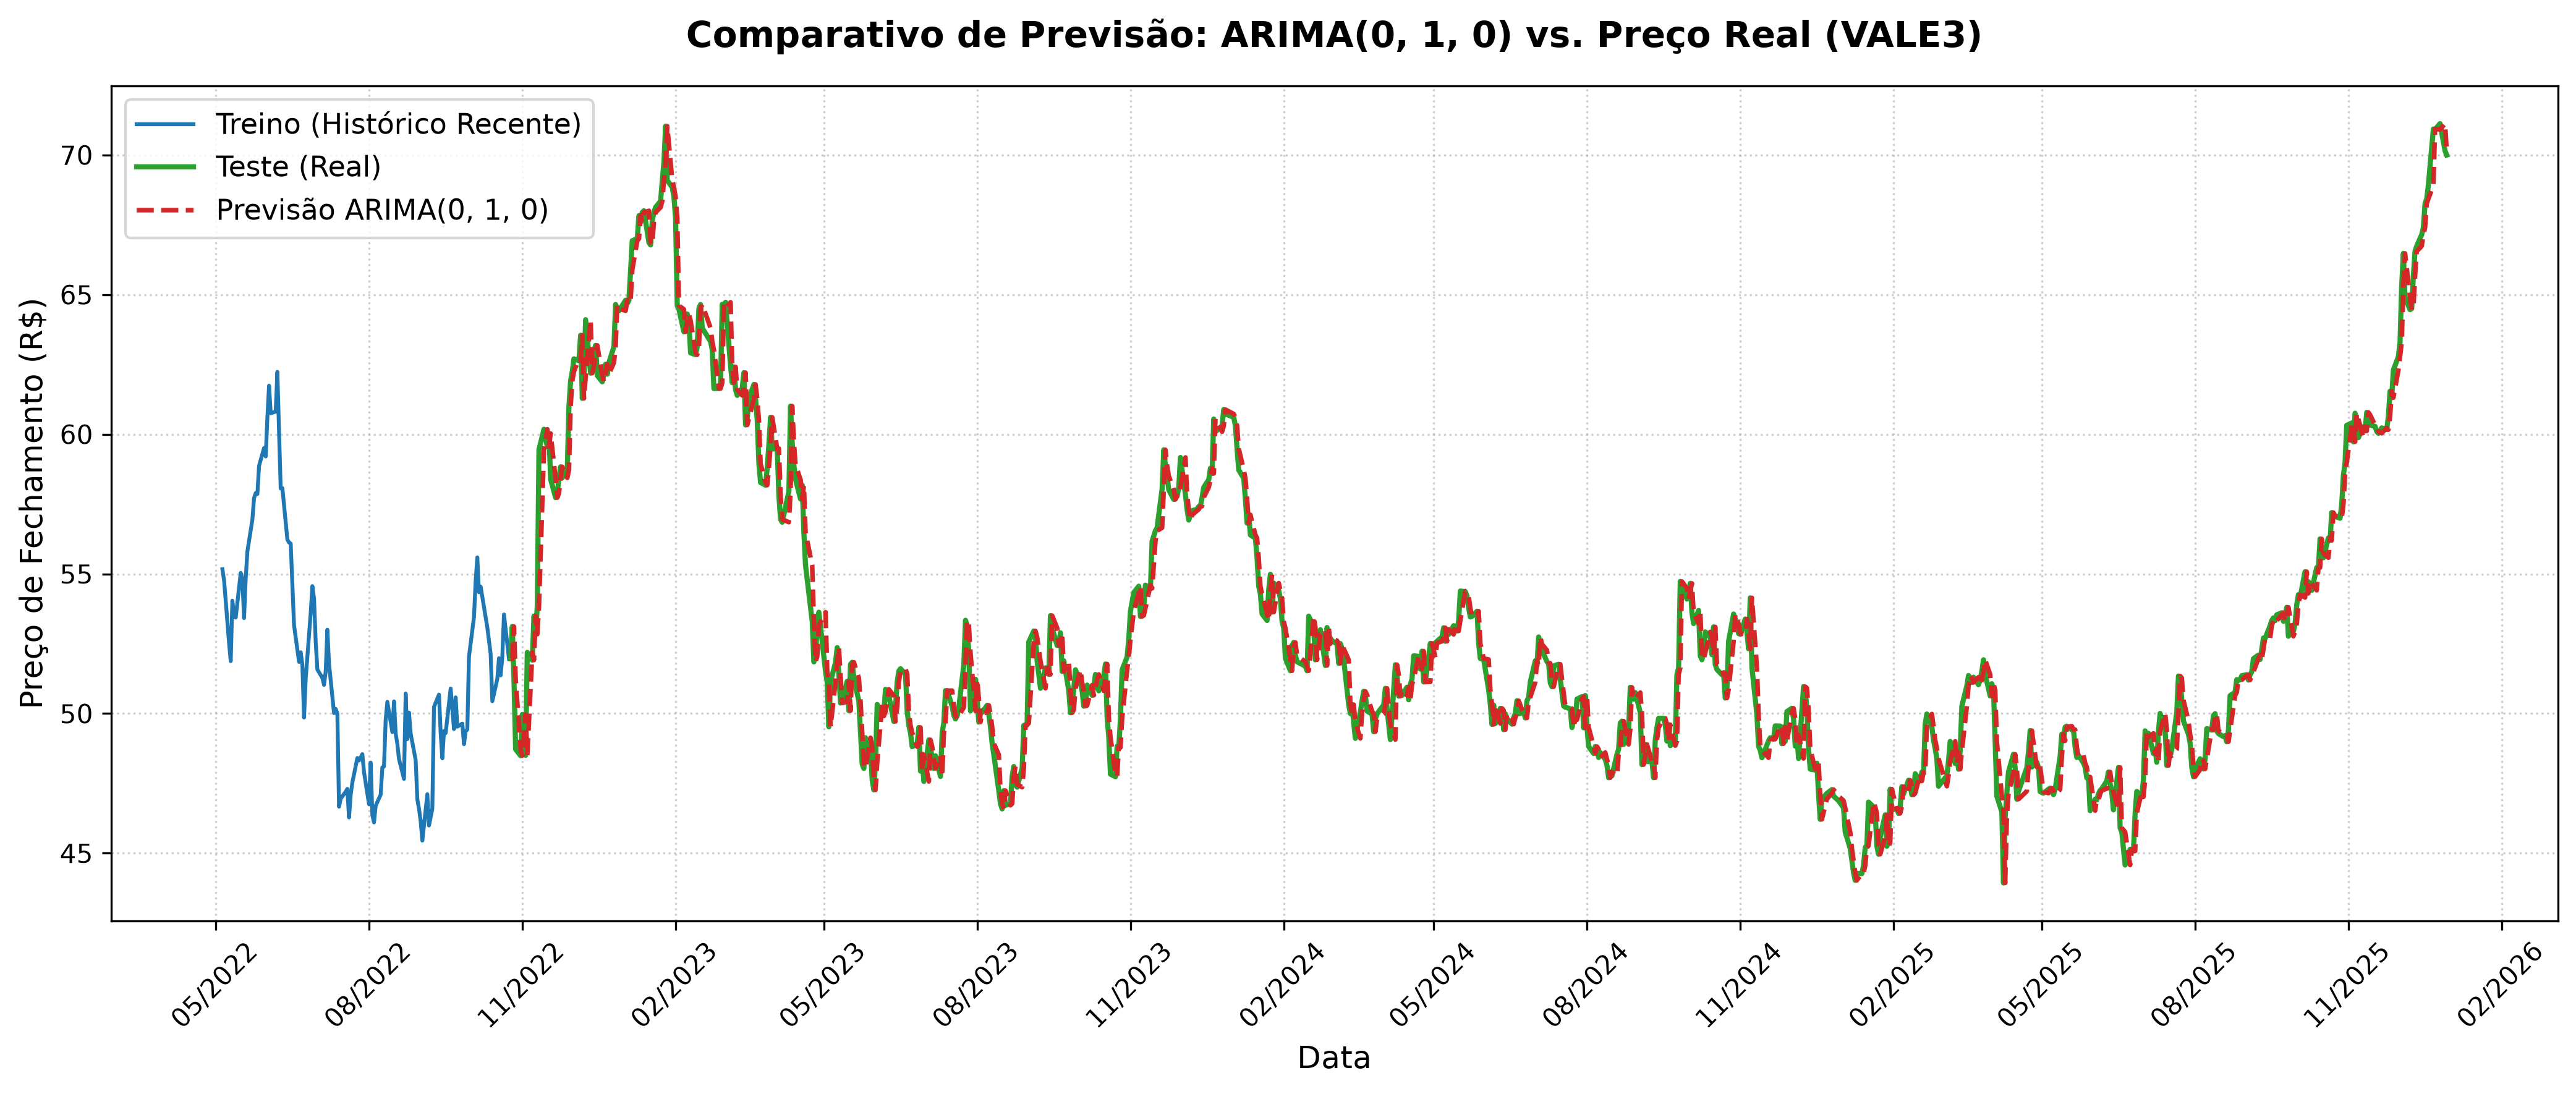

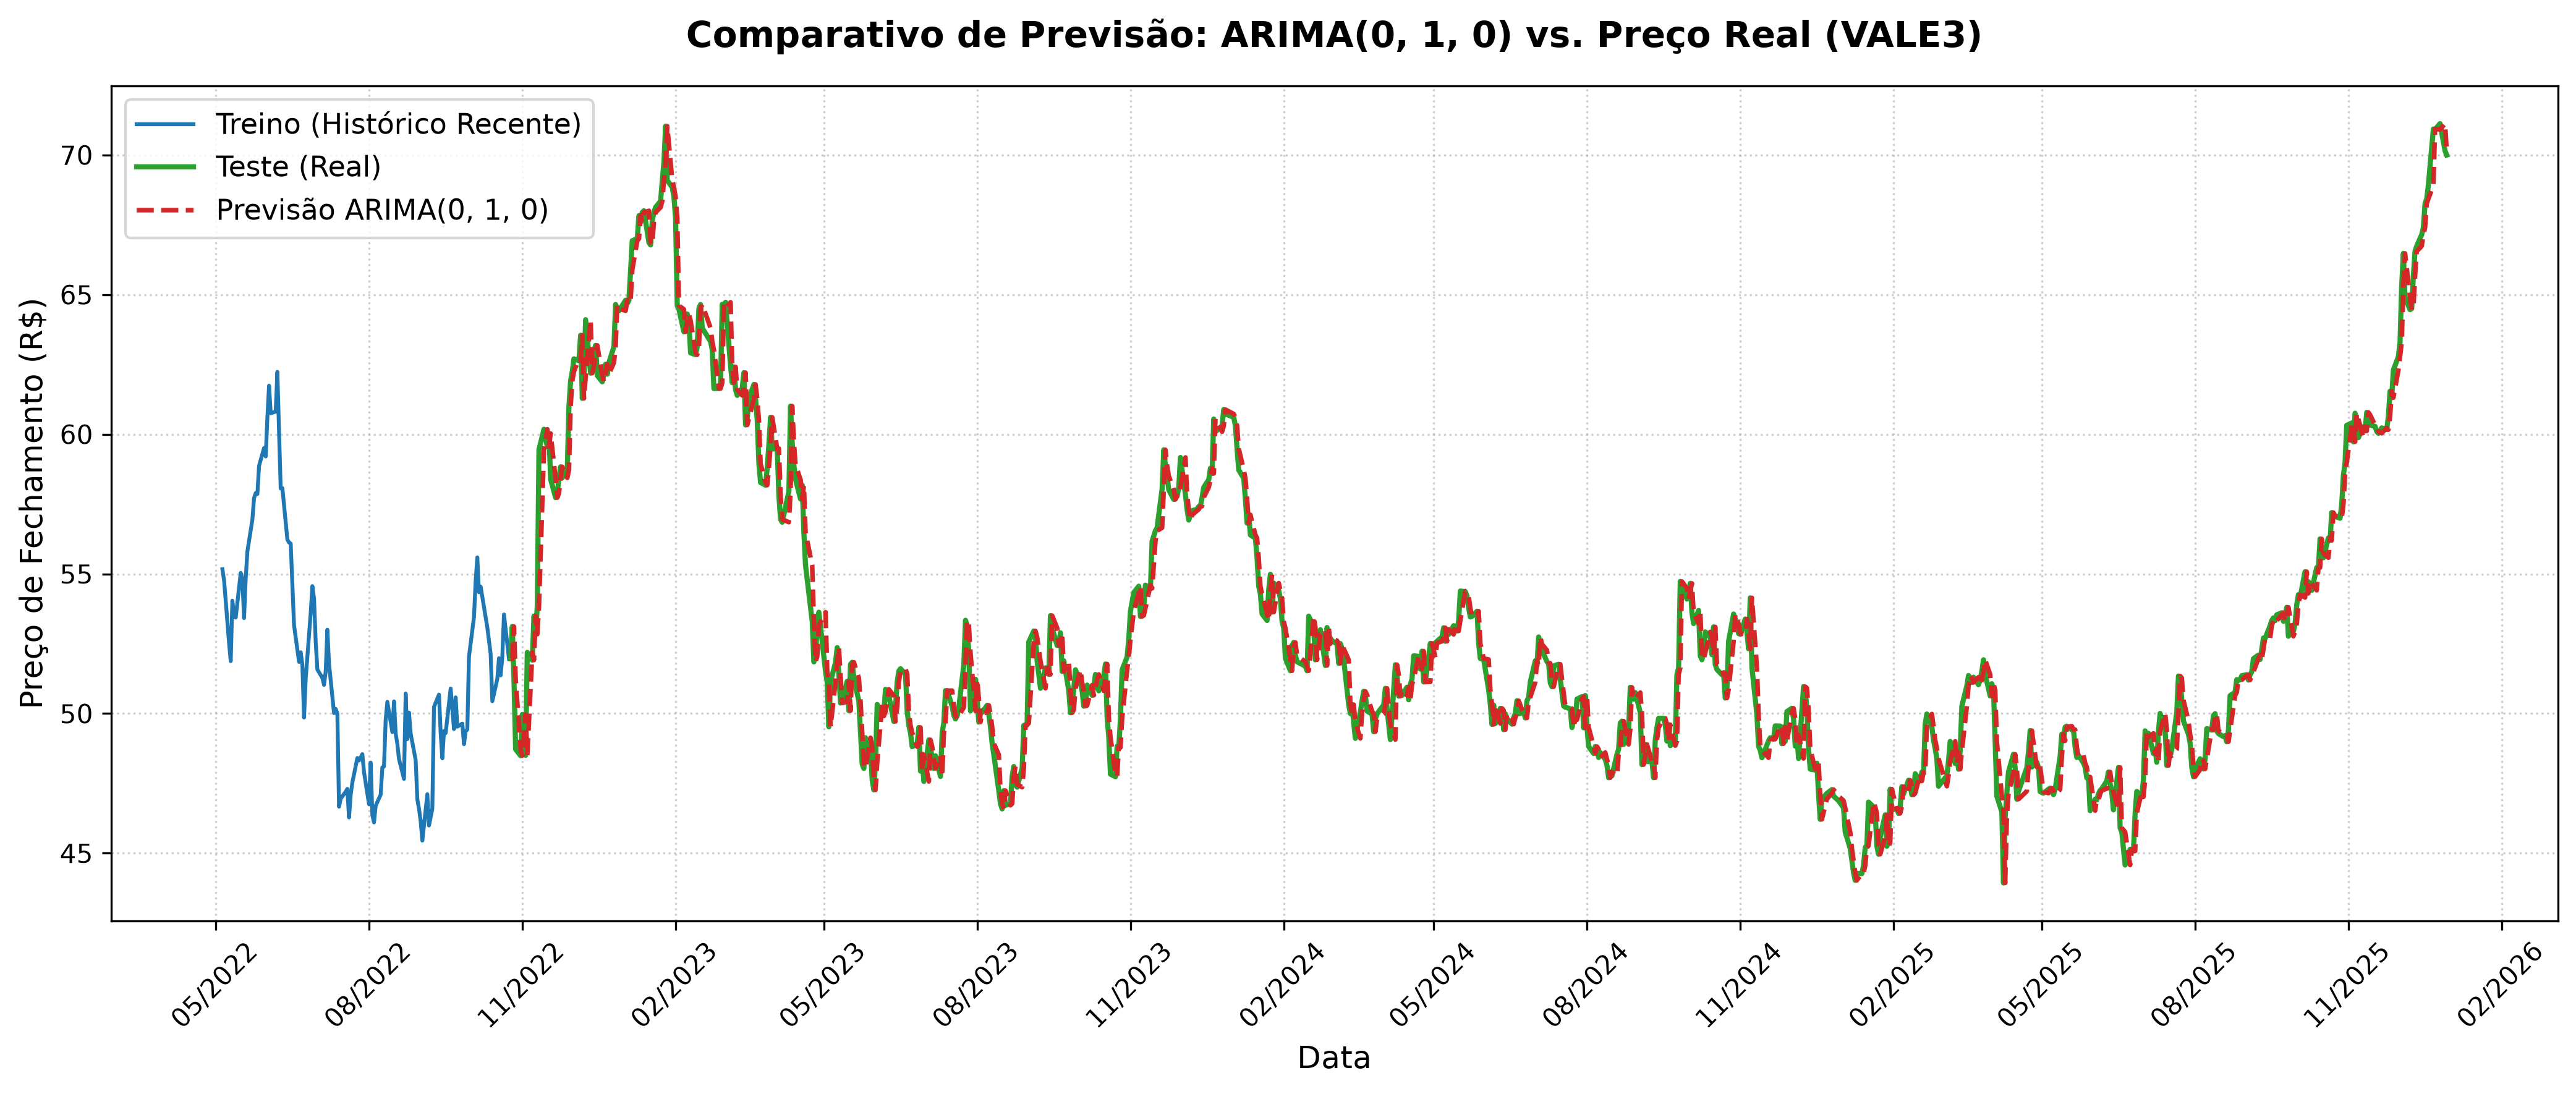

In [ ]:
plot_forecast(
    train_vale, test_vale,
    predictions=res_vale["predictions"],
    stock_name="vale",
    model_name=f"ARIMA{res_vale['order']}",
    ticker_label="VALE3",
)

## XGBooster

In [ ]:
res = run_xgbooster(train_vale, test_vale, "vale")
plot_forecast(train_vale, test_vale, res["predictions"], "vale",
              model_name="XGBoost", ticker_label="VALE3")